# Demo 1: Point-based Segmentation — SAM

**Model:** `facebook/sam-vit-base`  
**Task:** Click points on a fellow student's photo to segment any region

---
**Flow:**
1. Capture image from webcam (or load from file)
2. Load SAM model
3. Click points interactively → run segmentation


In [2]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
sys.path.insert(0, '..')  # allow running from notebooks/ subdirectory too

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import cv2

import os
os.environ['CUDA_VISIBLE_DEVICES'] = '2'

import warnings
warnings.filterwarnings('ignore')

## Step 1: Capture Image

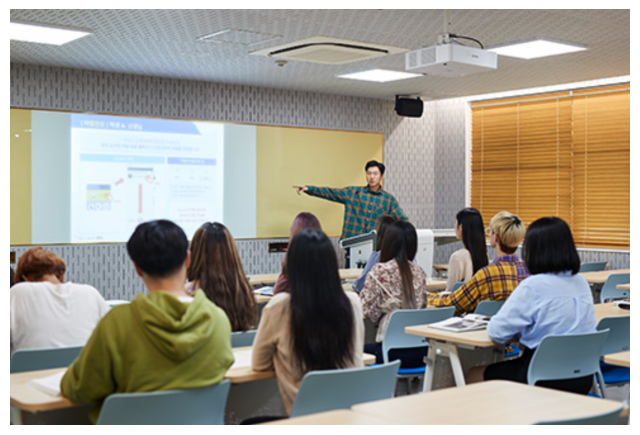

In [3]:
IMAGE_PATH = "sample.png"
image = Image.open(IMAGE_PATH).convert("RGB")
plt.figure(figsize=(8, 6))
plt.imshow(image); plt.axis('off'); plt.show()

## Step 2: Load SAM Model

In [4]:
from models.sam_model import SAMSegmentor

sam = SAMSegmentor()
sam.load()   # downloads model on first run (~375 MB)

[SAM] Loading facebook/sam-vit-base on cuda ...
[SAM] Model loaded.


## Step 3: Click Points on the Image

- **Left click** → Foreground (red dot, region to include)  
- **Undo button** → remove last point  
- **Clear button** → reset all points  

Once done, run the **Step 4** cell.


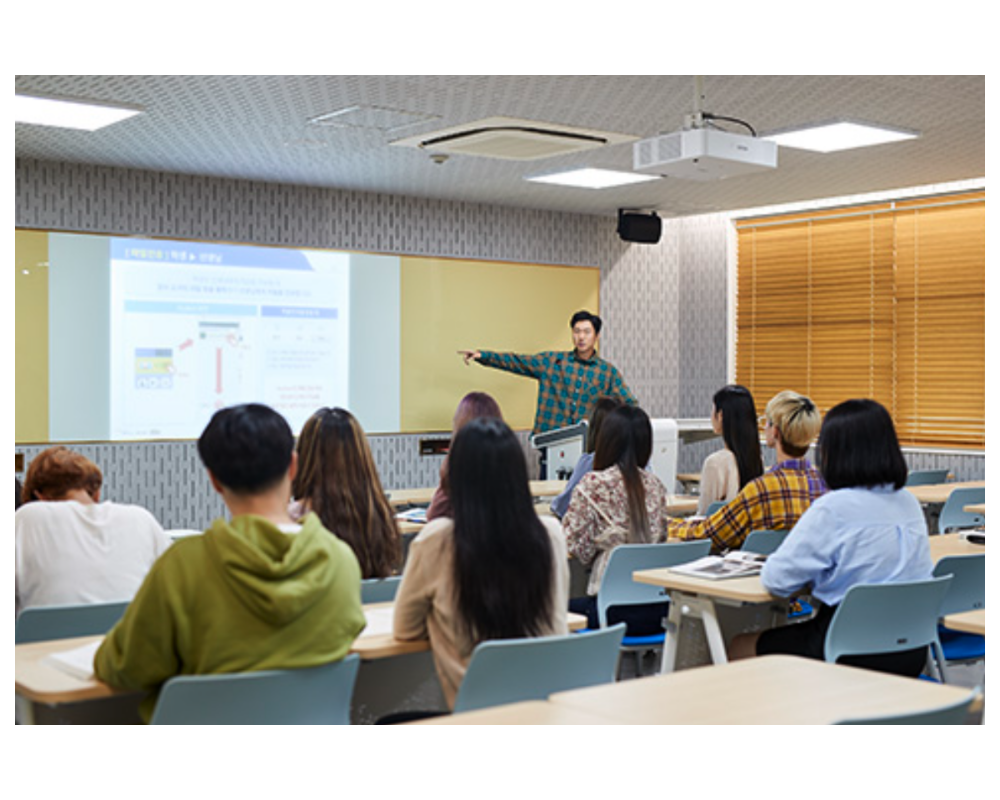

In [5]:
import ipympl  # noqa — registers the 'widget' backend entry point
import ipywidgets as widgets
from IPython.display import display
%matplotlib widget

INPUT_POINTS = []
INPUT_LABELS = []
scatter_artists = []

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(image)
# ax.set_title("Left click = Foreground (red)", fontsize=12)
ax.axis('off')
plt.tight_layout()

def redraw():
    for a in scatter_artists:
        a.remove()
    scatter_artists.clear()
    for (x, y), lbl in zip(INPUT_POINTS, INPUT_LABELS):
        color = 'red' if lbl == 1 else 'blue'
        a = ax.plot(x, y, 'o', color=color, markersize=12,
                    markeredgecolor='white', markeredgewidth=2)[0]
        scatter_artists.append(a)
    fig.canvas.draw_idle()

def on_click(event):
    if event.inaxes != ax or event.xdata is None:
        return
    x, y = int(event.xdata), int(event.ydata)
    label = 1 if event.button == 1 else 0
    INPUT_POINTS.append([x, y])
    INPUT_LABELS.append(label)
    redraw()
    tag = "FG" if label == 1 else "BG"
    print(f"[{tag}] ({x:4d}, {y:4d})  — total {len(INPUT_POINTS)} point(s)  |  "
          f"points={INPUT_POINTS}  labels={INPUT_LABELS}")

fig.canvas.mpl_connect('button_press_event', on_click)

btn_undo  = widgets.Button(description='Undo', button_style='warning', layout=widgets.Layout(width='100px'))
btn_clear = widgets.Button(description='Clear', button_style='danger',  layout=widgets.Layout(width='100px'))

def on_undo(_):
    if INPUT_POINTS:
        p, l = INPUT_POINTS.pop(), INPUT_LABELS.pop()
        redraw()
        print(f"Undo: ({p[0]}, {p[1]}) removed  — {len(INPUT_POINTS)} point(s) remaining")

def on_clear(_):
    INPUT_POINTS.clear()
    INPUT_LABELS.clear()
    redraw()
    print("All points cleared.")

btn_undo.on_click(on_undo)
btn_clear.on_click(on_clear)
display(widgets.HBox([btn_undo, btn_clear]))
plt.show()

## Step 4: Run Segmentation

Runs SAM with the points collected above.


IoU score: 0.9727  |  Mask pixels: 60,709


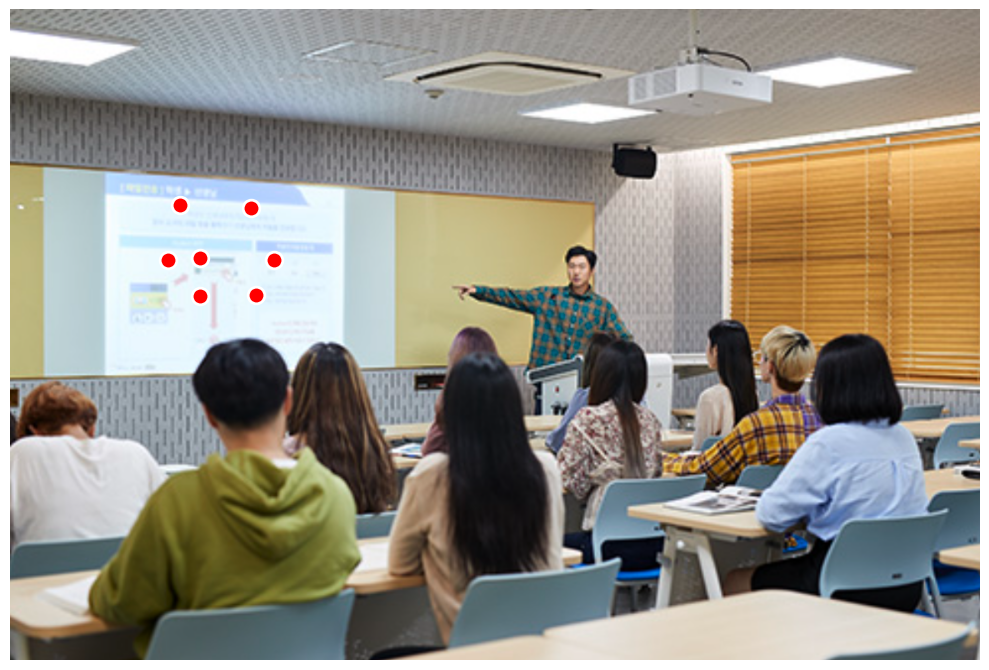

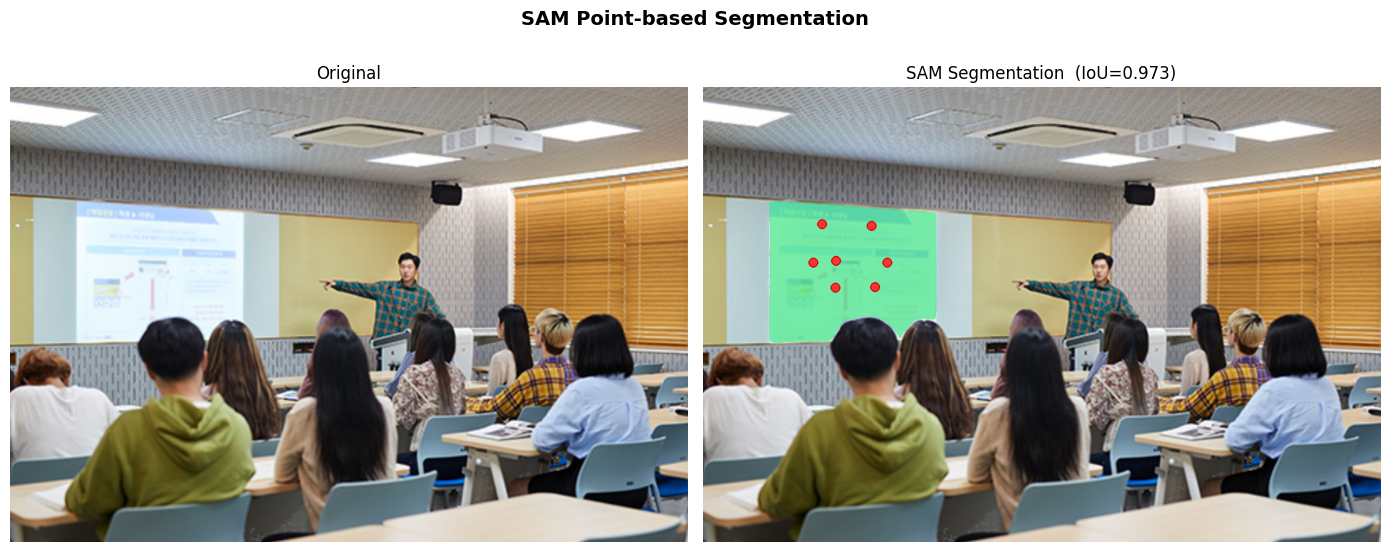

In [6]:
%matplotlib inline

from utils.visualization import draw_mask_on_image, draw_points_on_image

if not INPUT_POINTS:
    print("No points selected. Click on the image in Step 3 first.")
else:
    mask, iou_score = sam.predict(image, INPUT_POINTS, INPUT_LABELS)
    print(f"IoU score: {iou_score:.4f}  |  Mask pixels: {mask.sum():,}")

    result = draw_mask_on_image(image, mask, color=(0, 220, 80), alpha=0.5)
    result = draw_points_on_image(result, INPUT_POINTS, INPUT_LABELS)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(image);  axes[0].set_title("Original"); axes[0].axis('off')
    axes[1].imshow(result); axes[1].set_title(f"SAM Segmentation  (IoU={iou_score:.3f})"); axes[1].axis('off')

    plt.suptitle("SAM Point-based Segmentation", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()